# Predicting Student Health Risk — Playground Series S6E7

**Author:** Sahan Chathuranga Thilakarathna  
**Module:** Computational Intelligence  
**Competition:** https://www.kaggle.com/competitions/playground-series-s6e7  
**Evaluation metric:** Balanced accuracy (unweighted mean of per-class recall)

## Objective
Predict a three-class health condition label (`at-risk`, `unhealthy`, `fit`) for
university students from thirteen lifestyle and physiological measurements.

## Notebook structure
1. Environment and data loading  
2. Data profiling  
3. Exploratory data analysis  
4. Feature preparation  
5. Cross-validation framework  
6. Model development (five families)  
7. Ensemble and threshold optimisation  
8. Final submission and model export

## 1. Environment and data loading

The competition data is mounted read-only by the Kaggle runtime. No local
download is required, which keeps the notebook fully reproducible for any
user who forks it.

In [2]:
import os
for root, dirs, files in os.walk('/kaggle/input'):
    for f in files:
        print(os.path.join(root, f))

/kaggle/input/competitions/playground-series-s6e7/sample_submission.csv
/kaggle/input/competitions/playground-series-s6e7/train.csv
/kaggle/input/competitions/playground-series-s6e7/test.csv


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.max_columns', 50)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA = '/kaggle/input/competitions/playground-series-s6e7/'
OUT  = '/kaggle/working/'

train = pd.read_csv(DATA + 'train.csv')
test  = pd.read_csv(DATA + 'test.csv')
sub   = pd.read_csv(DATA + 'sample_submission.csv')

print(f'Train : {train.shape[0]:,} rows × {train.shape[1]} columns')
print(f'Test  : {test.shape[0]:,} rows × {test.shape[1]} columns')

Train : 690,088 rows × 15 columns
Test  : 295,753 rows × 14 columns


## 2. Data profiling

Before any modelling decision is made, the structure of the dataset is
established: variable types, target distribution, and the extent and pattern
of missing values.

In [4]:
TARGET = 'health_condition'
ID     = 'id'

FEATURES = [c for c in train.columns if c not in (ID, TARGET)]
CAT_COLS = [c for c in FEATURES if train[c].dtype == 'object']
NUM_COLS = [c for c in FEATURES if c not in CAT_COLS]

print(f'Numerical features   ({len(NUM_COLS)}): {NUM_COLS}')
print(f'Categorical features ({len(CAT_COLS)}): {CAT_COLS}')

profile = pd.DataFrame({
    'dtype'      : train[FEATURES].dtypes.astype(str),
    'n_unique'   : train[FEATURES].nunique(),
    'n_missing'  : train[FEATURES].isna().sum(),
    'pct_missing': (train[FEATURES].isna().mean() * 100).round(2)
}).sort_values('pct_missing', ascending=False)

profile

Numerical features   (7): ['sleep_duration', 'heart_rate', 'bmi', 'calorie_expenditure', 'step_count', 'exercise_duration', 'water_intake']
Categorical features (6): ['diet_type', 'stress_level', 'sleep_quality', 'physical_activity_level', 'smoking_alcohol', 'gender']


,dtype,n_unique,n_missing,pct_missing
stress_level,object,3,82811,12.00
sleep_duration,float64,701,75999,11.01
sleep_quality,object,3,58331,8.45
calorie_expenditure,float64,2101,52853,7.66
water_intake,float64,400,43477,6.30
physical_activity_level,object,3,36621,5.31
smoking_alcohol,object,3,28582,4.14
gender,object,3,21373,3.10
step_count,float64,12807,13916,2.02
bmi,float64,1596,13898,2.01


In [5]:
dist = pd.DataFrame({
    'count'     : train[TARGET].value_counts(),
    'proportion': train[TARGET].value_counts(normalize=True).round(4)
})
print(dist)

print(f'\nImbalance ratio (majority : minority) = '
      f'{dist["count"].max() / dist["count"].min():.1f} : 1')
print('Majority-class balanced accuracy = 0.3333')

                   count  proportion
health_condition                    
at-risk           592561      0.8587
unhealthy          57724      0.0836
fit                39803      0.0577

Imbalance ratio (majority : minority) = 14.9 : 1
Majority-class balanced accuracy = 0.3333


## 3. Exploratory data analysis

### 3.1 Target distribution and missingness overview

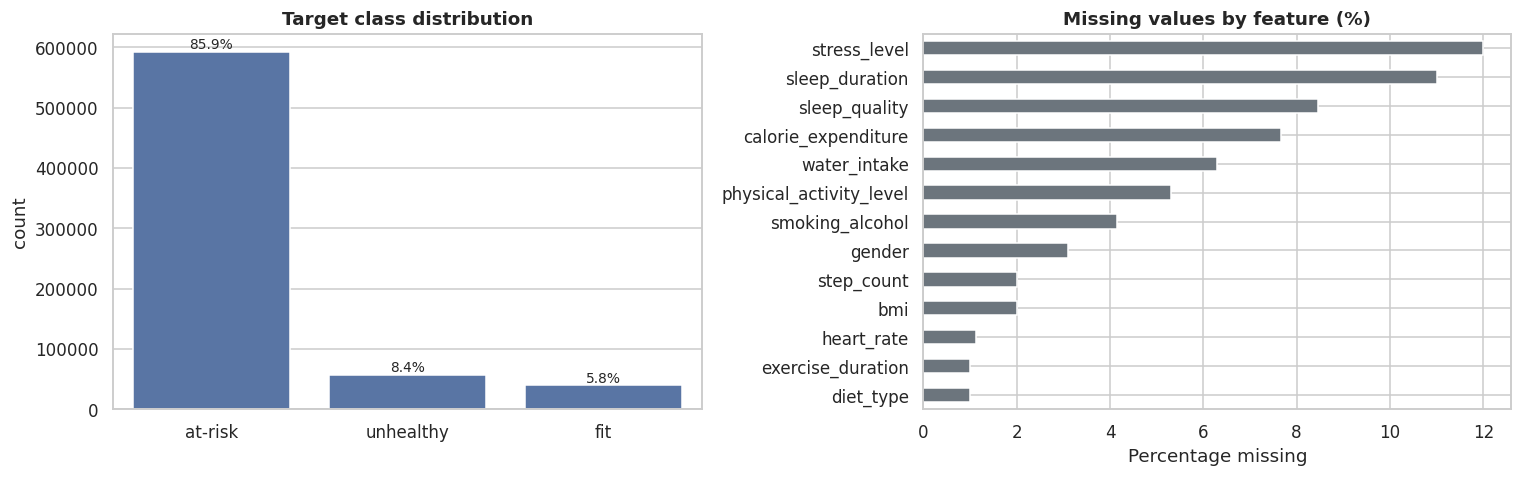

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

order = train[TARGET].value_counts().index
sns.countplot(data=train, x=TARGET, order=order, ax=axes[0])
axes[0].set_title('Target class distribution', fontweight='bold')
axes[0].set_xlabel('')
for p in axes[0].patches:
    axes[0].annotate(f'{p.get_height()/len(train):.1%}',
                     (p.get_x() + p.get_width()/2, p.get_height()),
                     ha='center', va='bottom', fontsize=9)

na = (train[FEATURES].isna().mean() * 100).sort_values()
na.plot.barh(ax=axes[1], color='#6c757d')
axes[1].set_title('Missing values by feature (%)', fontweight='bold')
axes[1].set_xlabel('Percentage missing')

plt.tight_layout()
plt.savefig(OUT + 'fig01_target_and_missingness.png', bbox_inches='tight')
plt.show()

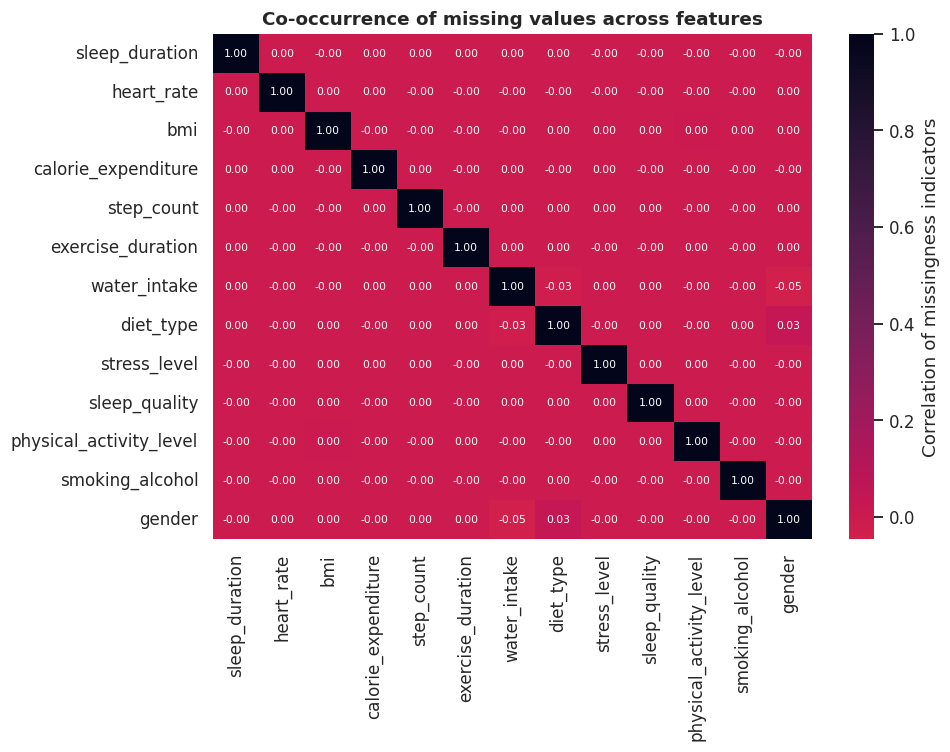

In [7]:
na_flags = train[FEATURES].isna().astype(int)
na_flags = na_flags.loc[:, na_flags.sum() > 0]

plt.figure(figsize=(9, 7))
sns.heatmap(na_flags.corr(), cmap='rocket_r', center=0,
            annot=True, fmt='.2f', annot_kws={'size': 7},
            cbar_kws={'label': 'Correlation of missingness indicators'})
plt.title('Co-occurrence of missing values across features', fontweight='bold')
plt.tight_layout()
plt.savefig(OUT + 'fig02_missingness_correlation.png', bbox_inches='tight')
plt.show()

In [8]:
base = train[TARGET].value_counts(normalize=True)
rows = []

for c in na_flags.columns:
    cond = train.loc[train[c].isna(), TARGET].value_counts(normalize=True)
    rows.append({'feature': c,
                 **{f'{k}_shift': round(cond.get(k, 0) - base[k], 4)
                    for k in base.index}})

shift = pd.DataFrame(rows).set_index('feature')
print('Change in class proportion when the feature is MISSING')
print('(positive = class over-represented among missing rows)\n')
print(shift.sort_values(shift.columns[0], key=abs, ascending=False))

Change in class proportion when the feature is MISSING
(positive = class over-represented among missing rows)

                         at-risk_shift  unhealthy_shift  fit_shift
feature                                                           
bmi                             0.0301          -0.0544     0.0243
heart_rate                      0.0121          -0.0097    -0.0024
diet_type                       0.0089          -0.0021    -0.0068
exercise_duration              -0.0078           0.0050     0.0027
water_intake                   -0.0036           0.0032     0.0004
step_count                      0.0034          -0.0027    -0.0007
smoking_alcohol                -0.0019           0.0019    -0.0000
sleep_quality                   0.0010          -0.0015     0.0005
physical_activity_level         0.0008          -0.0003    -0.0005
sleep_duration                  0.0007          -0.0003    -0.0004
calorie_expenditure            -0.0006           0.0003     0.0003
gender            

### 3.3 Distribution of numerical features by class

Kernel density estimates reveal whether individual features separate the
classes on their own. Heavily overlapping distributions imply that predictive
signal resides in feature *interactions* rather than in marginal effects,
which motivates the choice of tree-based ensembles over linear models.

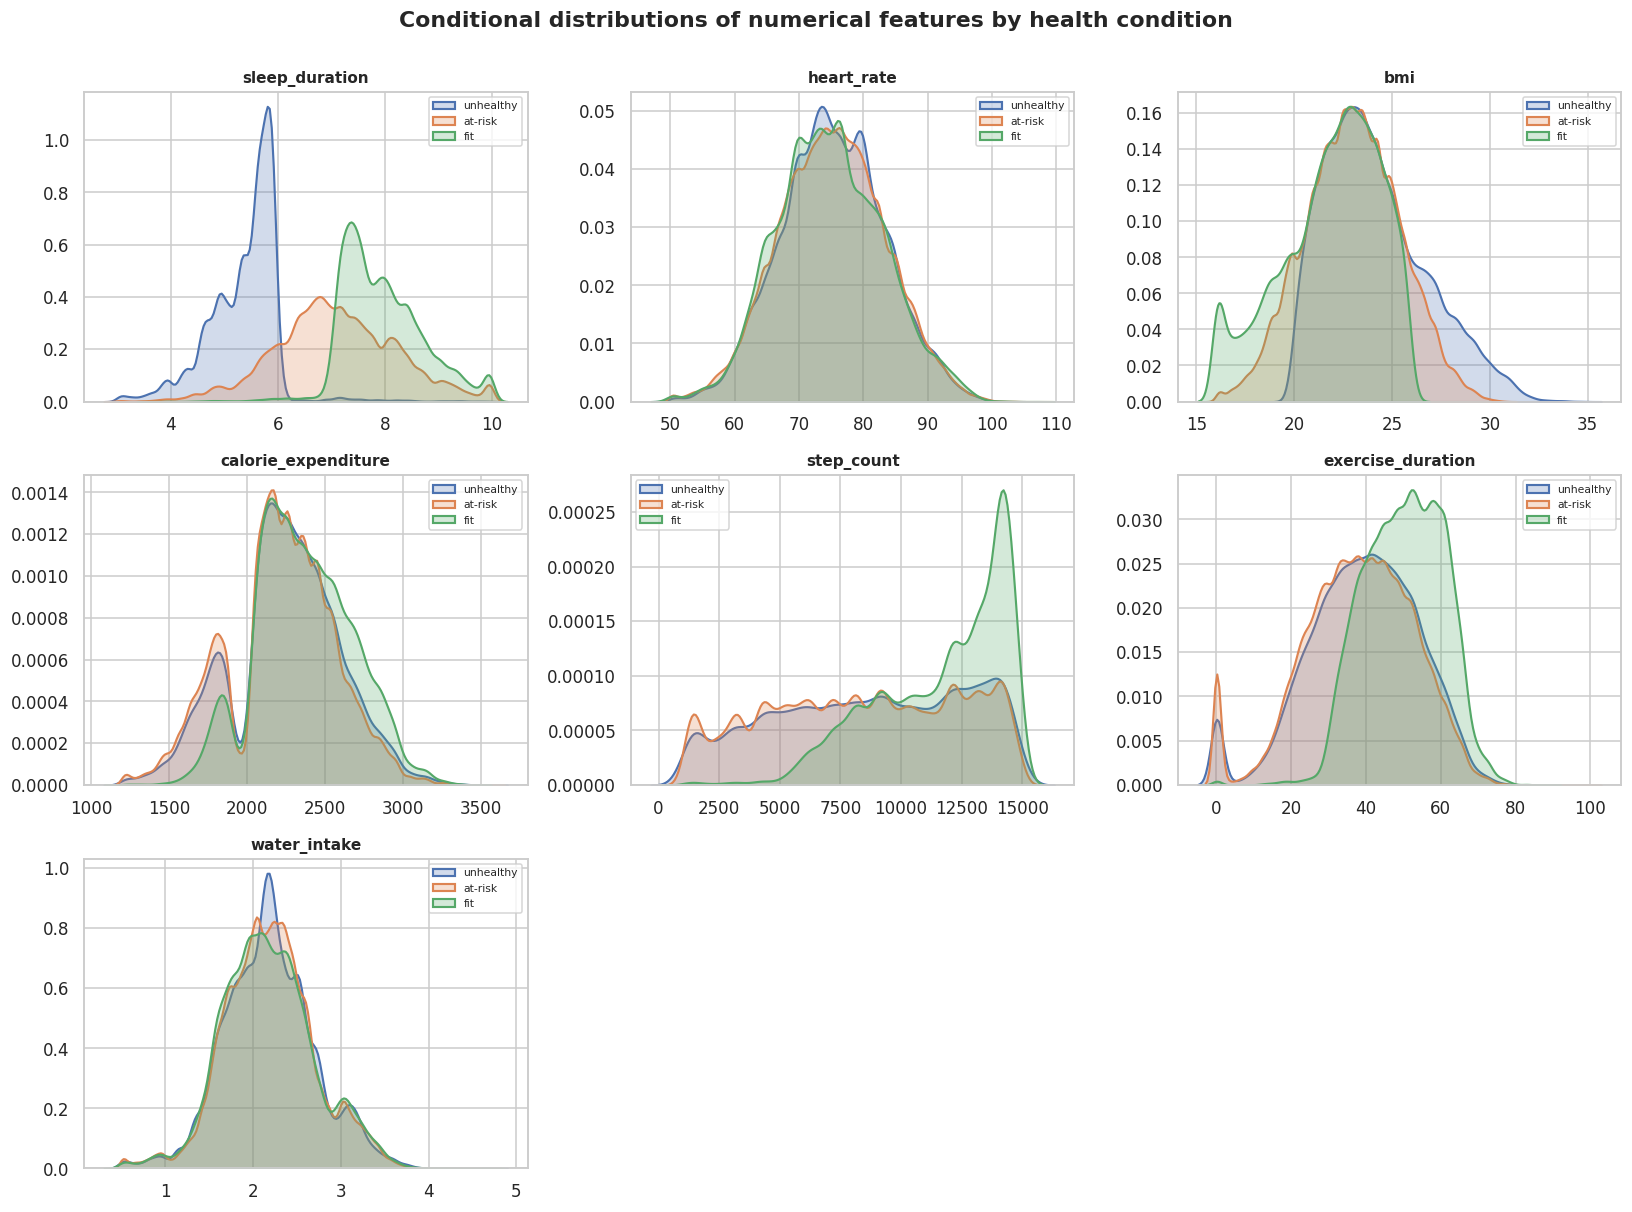

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
classes = train[TARGET].unique()

for ax, col in zip(axes.flat, NUM_COLS):
    for cls in classes:
        sns.kdeplot(train.loc[train[TARGET] == cls, col],
                    ax=ax, label=cls, fill=True, alpha=0.25, linewidth=1.4)
    ax.set_title(col, fontsize=10, fontweight='bold')
    ax.set_xlabel(''); ax.set_ylabel('')
    ax.legend(fontsize=7, title=None)

for ax in axes.flat[len(NUM_COLS):]:
    ax.axis('off')

fig.suptitle('Conditional distributions of numerical features by health condition',
             fontweight='bold', y=1.00)
plt.tight_layout()
plt.savefig(OUT + 'fig03_numeric_kde_by_class.png', bbox_inches='tight')
plt.show()

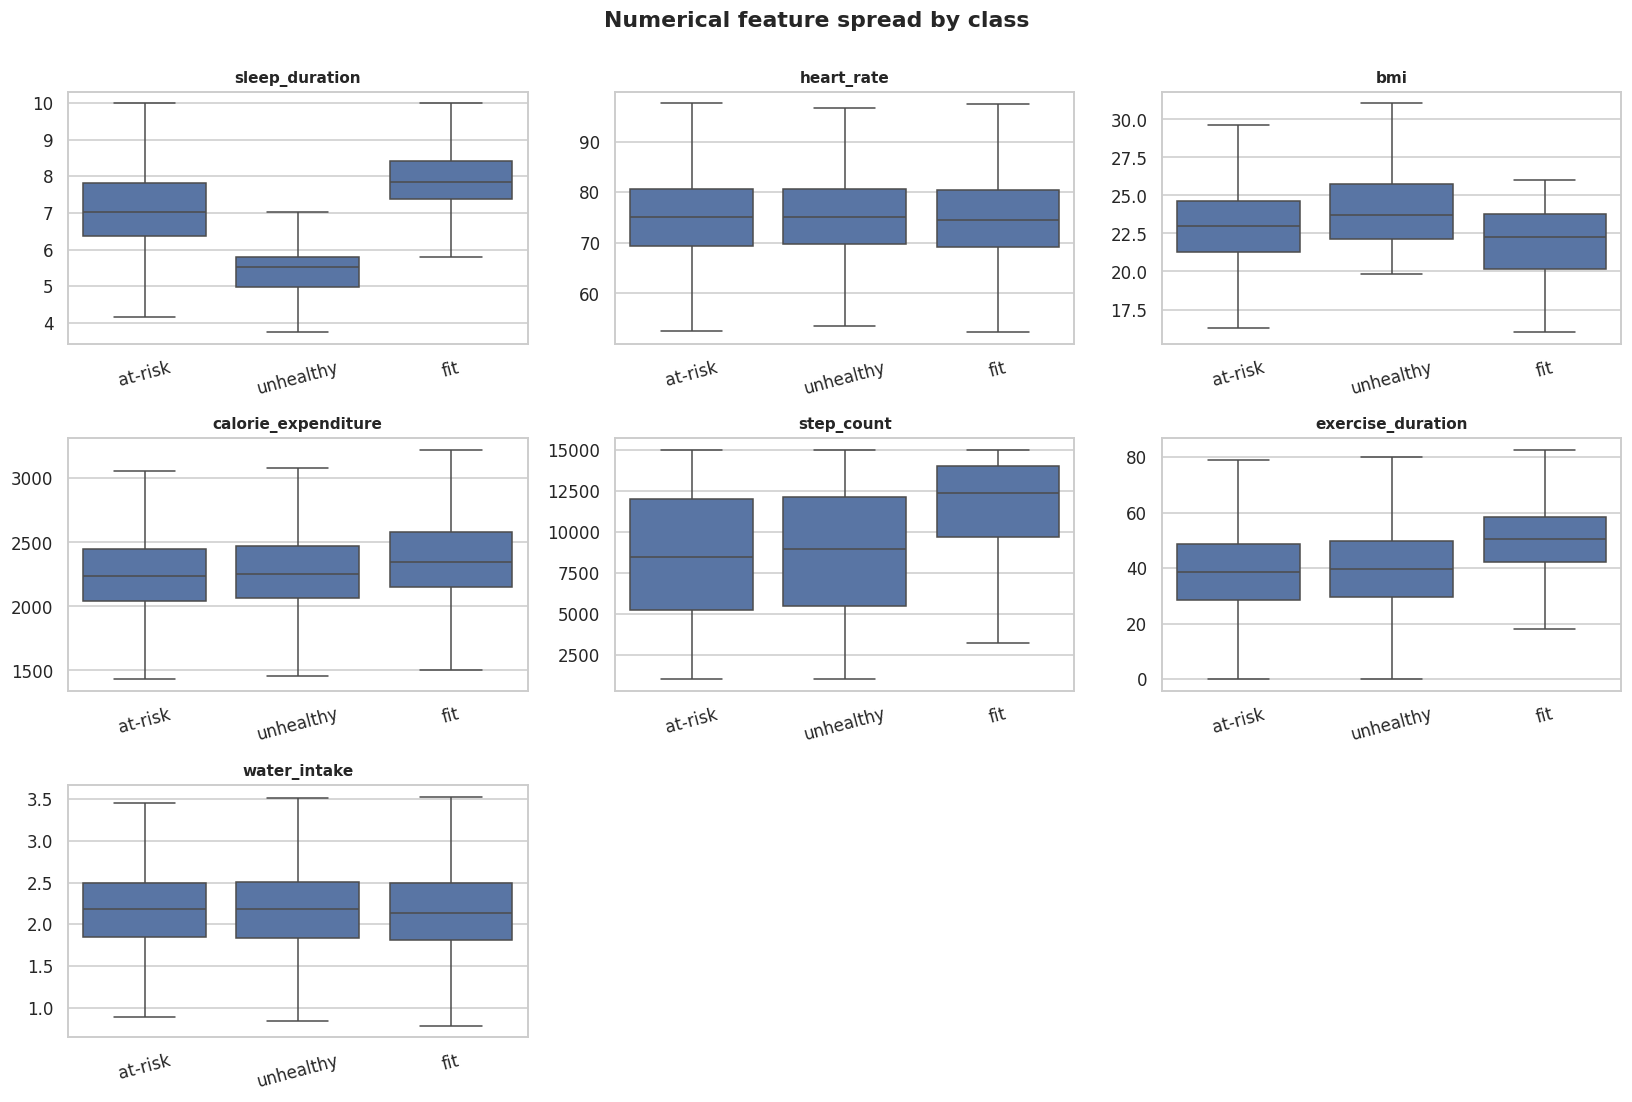

In [10]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10))

for ax, col in zip(axes.flat, NUM_COLS):
    sns.boxplot(data=train, x=TARGET, y=col, order=order, ax=ax, showfliers=False)
    ax.set_title(col, fontsize=10, fontweight='bold')
    ax.set_xlabel(''); ax.set_ylabel('')
    ax.tick_params(axis='x', rotation=15)

for ax in axes.flat[len(NUM_COLS):]:
    ax.axis('off')

fig.suptitle('Numerical feature spread by class', fontweight='bold', y=1.00)
plt.tight_layout()
plt.savefig(OUT + 'fig04_numeric_boxplots.png', bbox_inches='tight')
plt.show()

### 3.4 Categorical features and the target

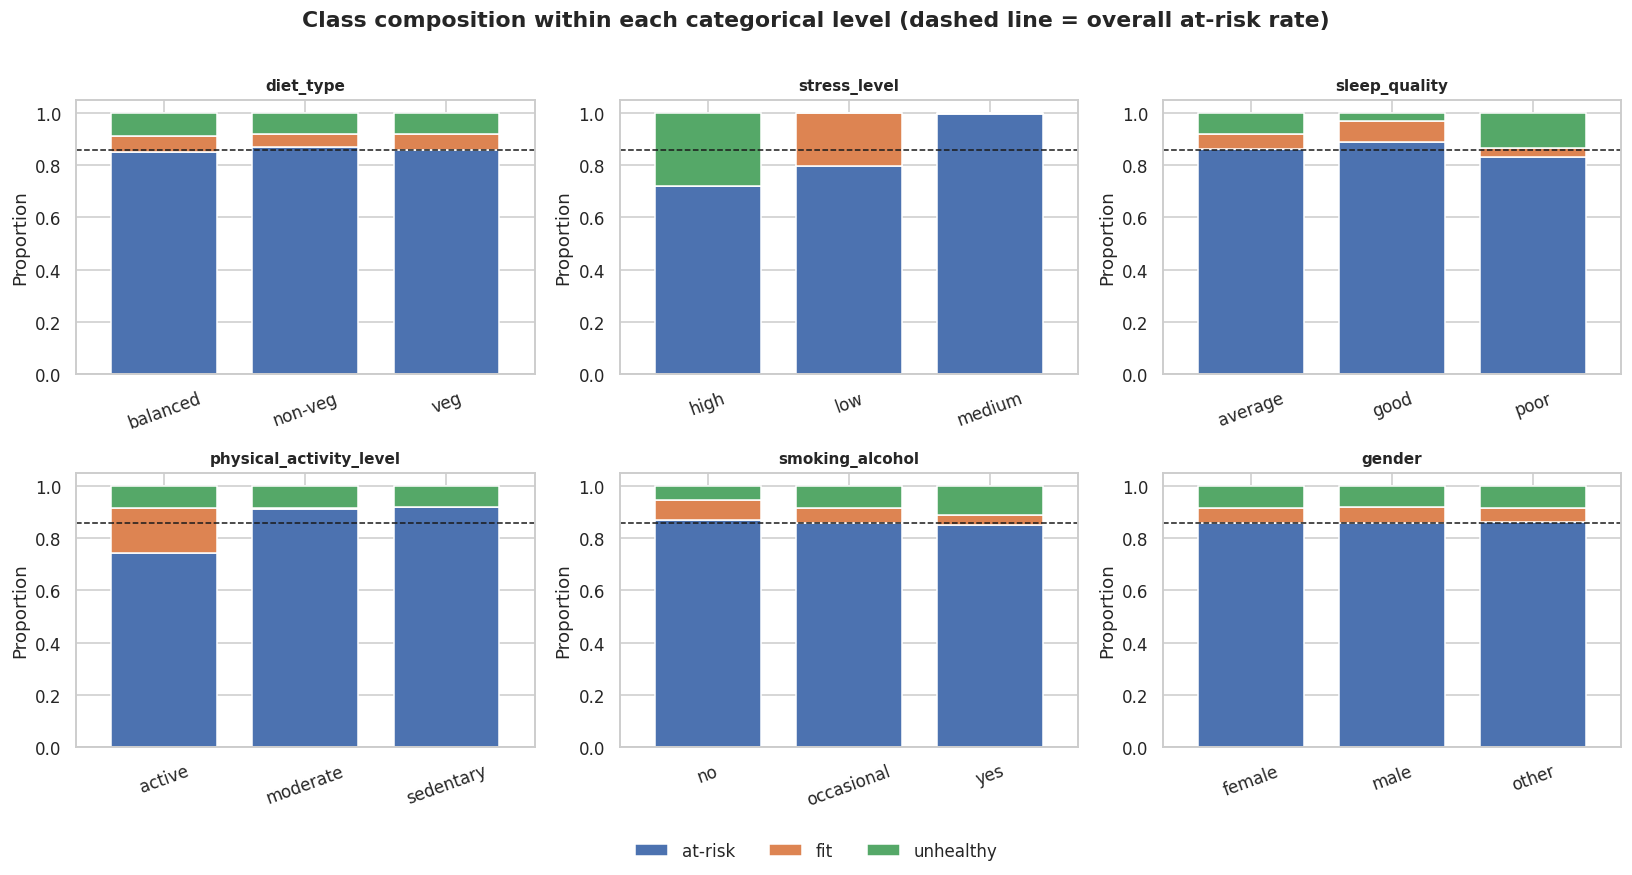

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.flat, CAT_COLS):
    ct = pd.crosstab(train[col], train[TARGET], normalize='index')
    ct.plot.bar(stacked=True, ax=ax, legend=False, width=0.75)
    ax.axhline(base['at-risk'], ls='--', lw=1, color='k')
    ax.set_title(col, fontsize=10, fontweight='bold')
    ax.set_xlabel(''); ax.set_ylabel('Proportion')
    ax.tick_params(axis='x', rotation=20)

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, frameon=False)
fig.suptitle('Class composition within each categorical level '
             '(dashed line = overall at-risk rate)', fontweight='bold')
plt.tight_layout(rect=[0, 0.05, 1, 0.97])
plt.savefig(OUT + 'fig05_categorical_vs_target.png', bbox_inches='tight')
plt.show()

### 3.5 Feature correlation and mutual information

Pearson correlation captures only monotonic linear association. Mutual
information is therefore computed alongside it, since it detects arbitrary
dependence including the non-monotonic relationships that tree ensembles are
able to exploit.

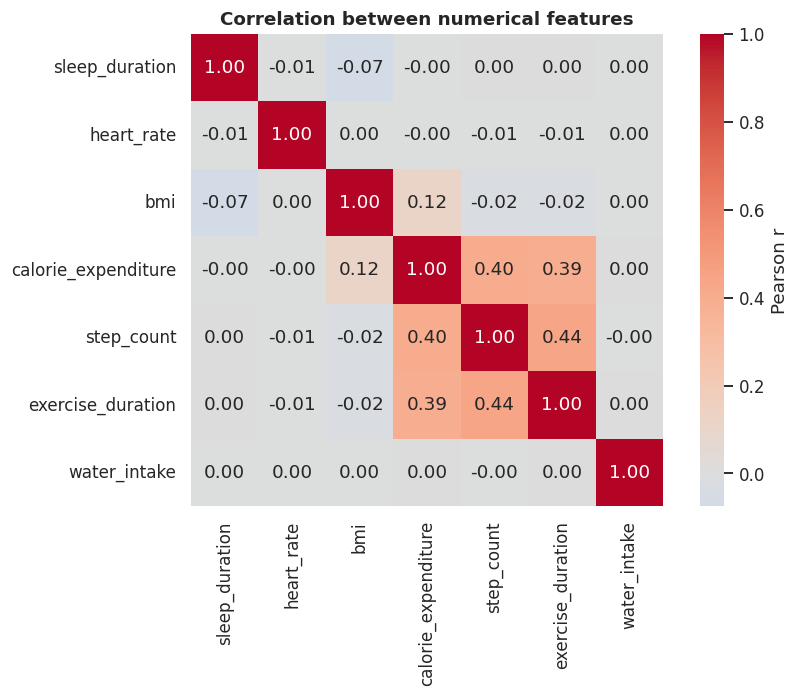

In [12]:
plt.figure(figsize=(8.5, 6.5))
sns.heatmap(train[NUM_COLS].corr(), annot=True, fmt='.2f',
            cmap='coolwarm', center=0, square=True,
            cbar_kws={'label': 'Pearson r'})
plt.title('Correlation between numerical features', fontweight='bold')
plt.tight_layout()
plt.savefig(OUT + 'fig06_correlation_matrix.png', bbox_inches='tight')
plt.show()

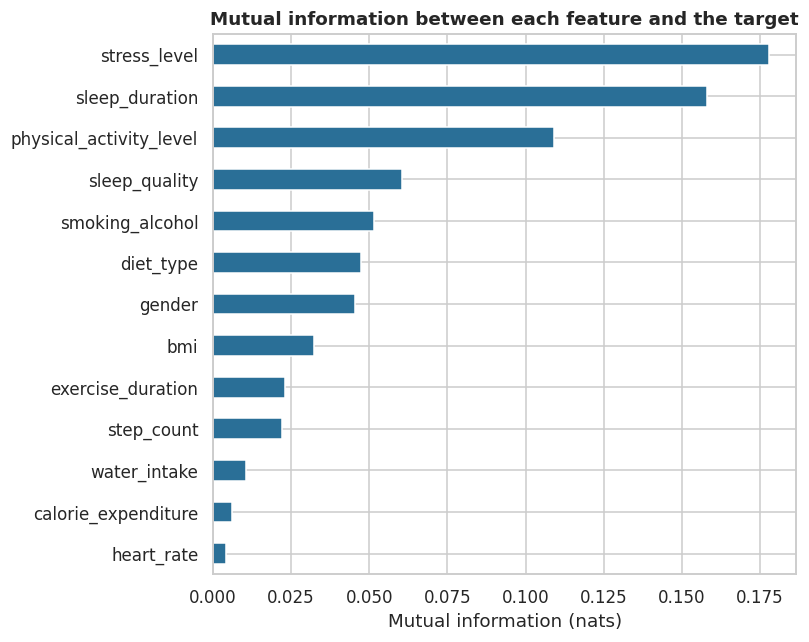

stress_level               0.17777
sleep_duration             0.15804
physical_activity_level    0.10913
sleep_quality              0.06054
smoking_alcohol            0.05161
diet_type                  0.04749
gender                     0.04541
bmi                        0.03243
exercise_duration          0.02296
step_count                 0.02209
water_intake               0.01074
calorie_expenditure        0.00627
heart_rate                 0.00419
dtype: float64


In [13]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder

mi_X = train[FEATURES].copy()
for c in CAT_COLS:
    mi_X[c] = mi_X[c].astype('category').cat.codes
mi_X = mi_X.fillna(-999)

mi = pd.Series(
    mutual_info_classif(mi_X, train[TARGET], random_state=RANDOM_STATE),
    index=FEATURES).sort_values()

plt.figure(figsize=(7.5, 6))
mi.plot.barh(color='#2a6f97')
plt.title('Mutual information between each feature and the target',
          fontweight='bold')
plt.xlabel('Mutual information (nats)')
plt.tight_layout()
plt.savefig(OUT + 'fig07_mutual_information.png', bbox_inches='tight')
plt.show()

print(mi.sort_values(ascending=False).round(5))

In [14]:
# A1 — categorical level names (needed for ordinal mappings)
for c in CAT_COLS:
    print(f'{c:<26}: {sorted(train[c].dropna().unique().tolist())}')

# A2 — train/test distribution consistency
print('\n--- Numeric means: train vs test ---')
print(pd.DataFrame({
    'train': train[NUM_COLS].mean(),
    'test' : test[NUM_COLS].mean(),
}).assign(pct_diff=lambda d: ((d.test - d.train) / d.train * 100).round(3)))

print('\n--- Missing rates: train vs test ---')
print(pd.DataFrame({
    'train': train[FEATURES].isna().mean(),
    'test' : test[FEATURES].isna().mean(),
}).round(4))

diet_type                 : ['balanced', 'non-veg', 'veg']
stress_level              : ['high', 'low', 'medium']
sleep_quality             : ['average', 'good', 'poor']
physical_activity_level   : ['active', 'moderate', 'sedentary']
smoking_alcohol           : ['no', 'occasional', 'yes']
gender                    : ['female', 'male', 'other']

--- Numeric means: train vs test ---
                           train         test  pct_diff
sleep_duration          6.992597     6.993517     0.013
heart_rate             75.096504    75.079560    -0.023
bmi                    22.984925    22.984661    -0.001
calorie_expenditure  2226.084931  2225.514941    -0.026
step_count           8615.953050  8626.630524     0.124
exercise_duration      38.751456    38.796712     0.117
water_intake            2.188542     2.191508     0.136

--- Missing rates: train vs test ---
                          train    test
sleep_duration           0.1101  0.1101
heart_rate               0.0114  0.0114
bmi        

## 4. Feature preparation

### 4.1 Validation strategy justification

Train and test partitions were compared before any modelling decision. Feature
means differ by less than 0.14% across all seven numerical variables, and
missing-value rates are identical to four decimal places across all thirteen
features. The two partitions are therefore drawn from the same distribution,
and cross-validation performance may be treated as a reliable proxy for
leaderboard performance. This permits model selection to proceed against
out-of-fold estimates without consuming daily submission allowances.

### 4.2 Encoding and engineered features

Three of the six categorical variables are ordinal in nature and are mapped to
integer ranks reflecting their natural ordering. The remaining three are
nominal and retain categorical dtype for native handling by the gradient
boosting implementations.

Six engineered features are derived from the exploratory analysis of
Section 3, each motivated by a specific observation rather than added
speculatively.

In [15]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y = le.fit_transform(train[TARGET])
CLASSES, N_CLASSES = list(le.classes_), len(le.classes_)
print('Class encoding:', dict(zip(CLASSES, range(N_CLASSES))))

# Ordinal mappings (level names are alphabetical, so order is set explicitly)
ORDINAL_MAPS = {
    'stress_level'           : {'low': 0, 'medium': 1, 'high': 2},
    'sleep_quality'          : {'poor': 0, 'average': 1, 'good': 2},
    'physical_activity_level': {'sedentary': 0, 'moderate': 1, 'active': 2},
    'smoking_alcohol'        : {'no': 0, 'occasional': 1, 'yes': 2},
}
NOMINAL_COLS = ['diet_type', 'gender']

# Evidence-driven: only features whose missingness shifts the class
# distribution materially (Section 3.2)
NA_INDICATOR_COLS = ['bmi', 'heart_rate', 'diet_type']

# Medians computed on train only, reused for test to avoid leakage
SLEEP_MEDIAN = train['sleep_duration'].median()

def build_tree_features(df):
    X = df[FEATURES].copy()

    for c in NA_INDICATOR_COLS:
        X[f'{c}_isna'] = df[c].isna().astype(np.int8)

    for c, m in ORDINAL_MAPS.items():
        X[c] = df[c].map(m).astype('float32')      # NaN preserved for LightGBM

    # E1 — sleep bands matching the class-conditional modes (Figure 3)
    X['sleep_band'] = pd.cut(df['sleep_duration'],
                             bins=[-np.inf, 6.0, 7.0, 8.0, np.inf],
                             labels=[0, 1, 2, 3]).astype('float32')

    # E2 — composite activity index over the correlated activity cluster
    act = df[['step_count', 'exercise_duration', 'calorie_expenditure']]
    X['activity_index'] = ((act - act.mean()) / act.std()).mean(axis=1)

    # E3 — zero-inflation in exercise_duration
    X['is_sedentary'] = (df['exercise_duration'] == 0).astype(np.int8)

    # E4/E5 — efficiency ratios
    X['steps_per_minute']  = df['step_count'] / df['exercise_duration'].replace(0, np.nan)
    X['calories_per_step'] = df['calorie_expenditure'] / df['step_count'].replace(0, np.nan)

    # E6 — interaction of the two highest-MI features (NaN preserved)
    X['sleep_stress_ratio'] = df['sleep_duration'] / (X['stress_level'] + 1)

    # E7 — imputed variant of E6, defined on all rows for the dense pipeline
    sd = df['sleep_duration'].fillna(SLEEP_MEDIAN)
    st = X['stress_level'].fillna(1.0)             # 1 = medium
    X['sleep_stress_ratio_filled'] = sd / (st + 1)

    for c in NOMINAL_COLS:
        X[c] = X[c].astype('category')

    return X

X_tree      = build_tree_features(train)
X_tree_test = build_tree_features(test)[X_tree.columns]

for c in NOMINAL_COLS:
    X_tree_test[c] = X_tree_test[c].cat.set_categories(X_tree[c].cat.categories)

ENGINEERED = [c for c in X_tree.columns if c not in FEATURES]
print(f'\nTree feature matrix: {X_tree.shape}')
print(f'Engineered ({len(ENGINEERED)}): {ENGINEERED}')
X_tree.head()

Class encoding: {'at-risk': 0, 'fit': 1, 'unhealthy': 2}

Tree feature matrix: (690088, 23)
Engineered (10): ['bmi_isna', 'heart_rate_isna', 'diet_type_isna', 'sleep_band', 'activity_index', 'is_sedentary', 'steps_per_minute', 'calories_per_step', 'sleep_stress_ratio', 'sleep_stress_ratio_filled']


,sleep_duration,heart_rate,bmi,calorie_expenditure,step_count,exercise_duration,water_intake,diet_type,stress_level,sleep_quality,physical_activity_level,smoking_alcohol,gender,bmi_isna,heart_rate_isna,diet_type_isna,sleep_band,activity_index,is_sedentary,steps_per_minute,calories_per_step,sleep_stress_ratio,sleep_stress_ratio_filled
0,5.22,70.6,25.66,2174.0,1326.0,19.8,1.86,veg,2.0,1.0,0.0,2.0,female,0,0,0,0.0,-1.096876,0,66.969697,1.639517,1.740000,1.740000
1,5.53,71.3,25.84,1966.0,9891.0,49.9,1.26,non-veg,0.0,1.0,1.0,2.0,other,0,0,0,0.0,0.110782,0,198.216433,0.198767,5.530000,5.530000
2,5.29,75.4,24.54,2688.0,14216.0,38.1,1.60,veg,2.0,0.0,2.0,2.0,male,0,0,0,0.0,0.903368,0,373.123360,0.189083,1.763333,1.763333
3,4.70,77.2,23.13,2630.0,7174.0,59.9,2.02,veg,2.0,1.0,2.0,1.0,female,0,0,0,0.0,0.743277,0,119.766277,0.366602,1.566667,1.566667
4,7.23,73.4,28.44,2560.0,6584.0,46.0,2.25,veg,NaN,1.0,0.0,NaN,male,0,0,0,2.0,0.311797,0,143.130435,0.388821,NaN,3.615000


In [16]:
from sklearn.feature_selection import mutual_info_classif

new_cols = [c for c in ENGINEERED if X_tree[c].dtype != 'category']
mi_new = pd.Series(
    mutual_info_classif(X_tree[new_cols].fillna(-999), y, random_state=RANDOM_STATE),
    index=new_cols).sort_values(ascending=False)

print('Mutual information of engineered features:')
print(mi_new.round(5))
print(f'\nReference — best original feature (stress_level): 0.17777')

Mutual information of engineered features:
sleep_stress_ratio           0.30384
sleep_stress_ratio_filled    0.29871
sleep_band                   0.14116
activity_index               0.02718
calories_per_step            0.01912
steps_per_minute             0.01102
is_sedentary                 0.00172
heart_rate_isna              0.00058
bmi_isna                     0.00040
diet_type_isna               0.00000
dtype: float64

Reference — best original feature (stress_level): 0.17777


In [17]:
print(pd.crosstab(train['sleep_duration'].isna(),
                  train['stress_level'].isna(), normalize=True).round(4))

TREE_COLS  = [c for c in X_tree.columns if c != 'sleep_stress_ratio_filled']
DENSE_COLS = [c for c in X_tree.columns if c != 'sleep_stress_ratio']
print(f'\nTree path : {len(TREE_COLS)} features')
print(f'Dense path: {len(DENSE_COLS)} features')

stress_level     False   True 
sleep_duration                
False           0.7829  0.1069
True            0.0971  0.0131

Tree path : 22 features
Dense path: 22 features


## 5. Cross-validation framework

A single stratified five-fold partition is defined once and reused by every
model. Stratification preserves the 15:1 class ratio within each fold, and a
fixed seed guarantees that all models are assessed on identical partitions —
a precondition both for a fair comparison table and for fitting ensemble
weights on out-of-fold predictions without leakage.

Two feature views are maintained. Gradient-boosted trees and the random forest
receive the interaction term with missing values preserved, since these
implementations learn an optimal default split direction for absent values.
Models requiring complete numerical input receive the median-imputed variant
instead. Supplying both views to a single model would introduce near-duplicate
columns and fragment feature importance.

In [18]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (balanced_accuracy_score, f1_score,
                             classification_report, confusion_matrix)

N_SPLITS = 5
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
FOLDS = list(cv.split(X_tree, y))

for i, (tr_idx, va_idx) in enumerate(FOLDS):
    p = pd.Series(y[va_idx]).value_counts(normalize=True).sort_index()
    print(f'Fold {i}: train={len(tr_idx):,}  valid={len(va_idx):,}  props={p.round(4).tolist()}')

RESULTS, OOF, TESTP = {}, {}, {}

def evaluate(name, oof_proba, verbose=True):
    pred = oof_proba.argmax(1)
    m = {'balanced_accuracy': balanced_accuracy_score(y, pred),
         'macro_f1'         : f1_score(y, pred, average='macro'),
         'accuracy'         : (pred == y).mean()}
    RESULTS[name] = m
    if verbose:
        print(f'\n{"="*58}\n{name}\n{"="*58}')
        for k, v in m.items():
            print(f'{k:<20}: {v:.5f}')
        print()
        print(classification_report(y, pred, target_names=CLASSES, digits=4))
    return m

Fold 0: train=552,070  valid=138,018  props=[0.8587, 0.0577, 0.0836]
Fold 1: train=552,070  valid=138,018  props=[0.8587, 0.0577, 0.0836]
Fold 2: train=552,070  valid=138,018  props=[0.8587, 0.0577, 0.0836]
Fold 3: train=552,071  valid=138,017  props=[0.8587, 0.0577, 0.0836]
Fold 4: train=552,071  valid=138,017  props=[0.8587, 0.0577, 0.0836]


In [19]:
import lightgbm as lgb, time

Xt, Xt_test = X_tree[TREE_COLS], X_tree_test[TREE_COLS]

lgb_params = dict(
    objective='multiclass', num_class=N_CLASSES,
    n_estimators=800, learning_rate=0.05, num_leaves=64,
    min_child_samples=50, colsample_bytree=0.8,
    subsample=0.8, subsample_freq=1,
    reg_alpha=0.1, reg_lambda=0.1,
    class_weight='balanced',
    n_jobs=-1, verbose=-1, random_state=RANDOM_STATE)

oof_lgb  = np.zeros((len(Xt), N_CLASSES))
test_lgb = np.zeros((len(Xt_test), N_CLASSES))
lgb_models, t0 = [], time.time()

for fold, (tr_idx, va_idx) in enumerate(FOLDS):
    model = lgb.LGBMClassifier(**lgb_params)
    model.fit(Xt.iloc[tr_idx], y[tr_idx],
              eval_set=[(Xt.iloc[va_idx], y[va_idx])],
              eval_metric='multi_logloss',
              callbacks=[lgb.early_stopping(100, verbose=False)])
    oof_lgb[va_idx]  = model.predict_proba(Xt.iloc[va_idx])
    test_lgb        += model.predict_proba(Xt_test) / N_SPLITS
    lgb_models.append(model)
    print(f'Fold {fold}  best_iteration={model.best_iteration_}')

print(f'\nTraining time: {time.time()-t0:.1f}s')
OOF['LightGBM'], TESTP['LightGBM'] = oof_lgb, test_lgb
np.save(OUT + 'oof_lgb.npy', oof_lgb); np.save(OUT + 'test_lgb.npy', test_lgb)
evaluate('LightGBM', oof_lgb)

Fold 0  best_iteration=800
Fold 1  best_iteration=800
Fold 2  best_iteration=800
Fold 3  best_iteration=800
Fold 4  best_iteration=800

Training time: 767.6s

LightGBM
balanced_accuracy   : 0.94775
macro_f1            : 0.87747
accuracy            : 0.94602

              precision    recall  f1-score   support

     at-risk     0.9921    0.9454    0.9682    592561
         fit     0.7528    0.9444    0.8378     39803
   unhealthy     0.7293    0.9535    0.8265     57724

    accuracy                         0.9460    690088
   macro avg     0.8247    0.9478    0.8775    690088
weighted avg     0.9563    0.9460    0.9488    690088



{'balanced_accuracy': np.float64(0.9477543352351363),
 'macro_f1': 0.8774702940646909,
 'accuracy': np.float64(0.9460184788027034)}

In [20]:
from sklearn.preprocessing import LabelEncoder
_le = LabelEncoder(); _le.fit(train[TARGET])

sub[TARGET] = _le.inverse_transform(test_lgb.argmax(1))
sub.to_csv(OUT + 'submission_lgbm_baseline.csv', index=False)
print(sub[TARGET].value_counts(normalize=True).round(4))
print('\nTrain distribution:')
print(train[TARGET].value_counts(normalize=True).round(4))

health_condition
at-risk      0.8192
unhealthy    0.1092
fit          0.0716
Name: proportion, dtype: float64

Train distribution:
health_condition
at-risk      0.8587
unhealthy    0.0836
fit          0.0577
Name: proportion, dtype: float64


In [21]:
from sklearn.model_selection import GridSearchCV, StratifiedShuffleSplit
import lightgbm as lgb, time

# Smaller subsample + simpler grid for speed
sss = StratifiedShuffleSplit(n_splits=1, train_size=50_000, random_state=RANDOM_STATE)
gs_idx, _ = next(sss.split(Xt, y))
Xg, yg = Xt.iloc[gs_idx], y[gs_idx]

param_grid = {
    'num_leaves'    : [31, 64],
    'learning_rate' : [0.05, 0.1],
}

base = lgb.LGBMClassifier(
    objective='multiclass', num_class=N_CLASSES,
    n_estimators=300,                 
    class_weight='balanced', subsample=0.8, colsample_bytree=0.8,
    n_jobs=1,                        
    verbose=-1, random_state=RANDOM_STATE)

grid = GridSearchCV(
    estimator=base, param_grid=param_grid,
    scoring='balanced_accuracy', cv=3, n_jobs=-1, verbose=1)  # parallelism lives HERE only

t0 = time.time()
grid.fit(Xg, yg)
print(f'\nTuning time: {time.time()-t0:.1f}s')
print('Best parameters :', grid.best_params_)
print('Best CV balanced accuracy:', round(grid.best_score_, 5))

res = pd.DataFrame(grid.cv_results_)
print(res[['params', 'mean_test_score']]
      .sort_values('mean_test_score', ascending=False).to_string(index=False))

Fitting 3 folds for each of 4 candidates, totalling 12 fits

Tuning time: 62.8s
Best parameters : {'learning_rate': 0.05, 'num_leaves': 31}
Best CV balanced accuracy: 0.93029
                                   params  mean_test_score
{'learning_rate': 0.05, 'num_leaves': 31}         0.930290
{'learning_rate': 0.05, 'num_leaves': 64}         0.907996
 {'learning_rate': 0.1, 'num_leaves': 31}         0.906280
 {'learning_rate': 0.1, 'num_leaves': 64}         0.889901


In [22]:
import xgboost as xgb
from sklearn.utils.class_weight import compute_sample_weight


Xx      = Xt.copy()
Xx_test = Xt_test.copy()
for c in Xx.select_dtypes('category').columns:
    Xx[c]      = Xx[c].cat.codes
    Xx_test[c] = Xx_test[c].cat.codes

xgb_params = dict(
    objective='multi:softprob', num_class=N_CLASSES,
    n_estimators=800, learning_rate=0.05, max_depth=8,
    subsample=0.8, colsample_bytree=0.8,
    reg_alpha=0.1, reg_lambda=1.0,
    tree_method='hist', n_jobs=-1,
    eval_metric='mlogloss', random_state=RANDOM_STATE)

oof_xgb  = np.zeros((len(Xx), N_CLASSES))
test_xgb = np.zeros((len(Xx_test), N_CLASSES))
t0 = time.time()

for fold, (tr_idx, va_idx) in enumerate(FOLDS):
    sw = compute_sample_weight('balanced', y[tr_idx])
    model = xgb.XGBClassifier(**xgb_params)
    model.fit(Xx.iloc[tr_idx], y[tr_idx], sample_weight=sw,
              eval_set=[(Xx.iloc[va_idx], y[va_idx])], verbose=False)
    oof_xgb[va_idx]  = model.predict_proba(Xx.iloc[va_idx])
    test_xgb        += model.predict_proba(Xx_test) / N_SPLITS
    print(f'Fold {fold} done')

print(f'\nTraining time: {time.time()-t0:.1f}s')
OOF['XGBoost'], TESTP['XGBoost'] = oof_xgb, test_xgb
np.save(OUT + 'oof_xgb.npy', oof_xgb); np.save(OUT + 'test_xgb.npy', test_xgb)
evaluate('XGBoost', oof_xgb)

Fold 0 done
Fold 1 done
Fold 2 done
Fold 3 done
Fold 4 done

Training time: 1033.5s

XGBoost
balanced_accuracy   : 0.94590
macro_f1            : 0.87945
accuracy            : 0.94724

              precision    recall  f1-score   support

     at-risk     0.9914    0.9475    0.9689    592561
         fit     0.7586    0.9412    0.8401     39803
   unhealthy     0.7365    0.9490    0.8293     57724

    accuracy                         0.9472    690088
   macro avg     0.8288    0.9459    0.8795    690088
weighted avg     0.9566    0.9472    0.9498    690088



{'balanced_accuracy': np.float64(0.945897477002349),
 'macro_f1': 0.8794505584168034,
 'accuracy': np.float64(0.9472415112275536)}

In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
import time


Xl      = Xx.copy()
Xl_test = Xx_test.copy()

oof_lr  = np.zeros((len(Xl), N_CLASSES))
test_lr = np.zeros((len(Xl_test), N_CLASSES))
t0 = time.time()

for fold, (tr_idx, va_idx) in enumerate(FOLDS):
    pipe = Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale',  StandardScaler()),
        ('clf',    LogisticRegression(
            multi_class='multinomial', solver='lbfgs',
            class_weight='balanced', C=1.0, max_iter=1000,
            random_state=RANDOM_STATE))
    ])
    pipe.fit(Xl.iloc[tr_idx], y[tr_idx])
    oof_lr[va_idx]  = pipe.predict_proba(Xl.iloc[va_idx])
    test_lr        += pipe.predict_proba(Xl_test) / N_SPLITS
    print(f'Fold {fold} done')

print(f'\nTraining time: {time.time()-t0:.1f}s')
OOF['LogisticReg'], TESTP['LogisticReg'] = oof_lr, test_lr
np.save(OUT + 'oof_lr.npy', oof_lr); np.save(OUT + 'test_lr.npy', test_lr)
evaluate('LogisticReg', oof_lr)

Fold 0 done
Fold 1 done
Fold 2 done
Fold 3 done
Fold 4 done

Training time: 43.5s

LogisticReg
balanced_accuracy   : 0.89255
macro_f1            : 0.70430
accuracy            : 0.83438

              precision    recall  f1-score   support

     at-risk     0.9877    0.8181    0.8950    592561
         fit     0.3552    0.9110    0.5111     39803
   unhealthy     0.5633    0.9485    0.7068     57724

    accuracy                         0.8344    690088
   macro avg     0.6354    0.8926    0.7043    690088
weighted avg     0.9158    0.8344    0.8571    690088



{'balanced_accuracy': np.float64(0.8925508462009798),
 'macro_f1': 0.7042957475302548,
 'accuracy': np.float64(0.8343776445902552)}

In [24]:
from catboost import CatBoostClassifier
import gc

Xc      = Xt.copy()
Xc_test = Xt_test.copy()
cat_features = [c for c in Xc.columns if str(Xc[c].dtype) == 'category']
for c in cat_features:
    Xc[c]      = Xc[c].astype(str).fillna('missing')
    Xc_test[c] = Xc_test[c].astype(str).fillna('missing')

cb_params = dict(
    loss_function='MultiClass', classes_count=N_CLASSES,
    iterations=800, learning_rate=0.05, depth=8,
    l2_leaf_reg=3.0, random_seed=RANDOM_STATE,
    auto_class_weights='Balanced',
    task_type='CPU', thread_count=4, verbose=False)

oof_cat  = np.zeros((len(Xc), N_CLASSES))
test_cat = np.zeros((len(Xc_test), N_CLASSES))
t0 = time.time()

for fold, (tr_idx, va_idx) in enumerate(FOLDS):
    model = CatBoostClassifier(**cb_params)
    model.fit(Xc.iloc[tr_idx], y[tr_idx],
              cat_features=cat_features,
              eval_set=(Xc.iloc[va_idx], y[va_idx]))
    oof_cat[va_idx]  = model.predict_proba(Xc.iloc[va_idx])
    test_cat        += model.predict_proba(Xc_test) / N_SPLITS
    del model; gc.collect()
    print(f'Fold {fold} done')

print(f'\nTraining time: {time.time()-t0:.1f}s')
OOF['CatBoost'], TESTP['CatBoost'] = oof_cat, test_cat
np.save(OUT + 'oof_cat.npy', oof_cat); np.save(OUT + 'test_cat.npy', test_cat)
evaluate('CatBoost', oof_cat)

Fold 0 done
Fold 1 done
Fold 2 done
Fold 3 done
Fold 4 done

Training time: 5195.5s

CatBoost
balanced_accuracy   : 0.94910
macro_f1            : 0.86524
accuracy            : 0.93888

              precision    recall  f1-score   support

     at-risk     0.9933    0.9359    0.9638    592561
         fit     0.7308    0.9490    0.8257     39803
   unhealthy     0.6937    0.9624    0.8062     57724

    accuracy                         0.9389    690088
   macro avg     0.8059    0.9491    0.8652    690088
weighted avg     0.9531    0.9389    0.9426    690088



{'balanced_accuracy': np.float64(0.9490982613110708),
 'macro_f1': 0.8652442825190398,
 'accuracy': np.float64(0.9388831569307103)}

In [25]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedShuffleSplit
import gc

Xr      = Xx.copy()
Xr_test = Xx_test.copy()
_med    = Xr.median()
Xr      = Xr.fillna(_med)
Xr_test = Xr_test.fillna(_med)

sss = StratifiedShuffleSplit(n_splits=1, train_size=200_000, random_state=RANDOM_STATE)
sub_idx, _ = next(sss.split(Xr, y))
Xr_sub, y_sub = Xr.iloc[sub_idx], y[sub_idx]

rf_params = dict(
    n_estimators=300, max_depth=18, min_samples_leaf=20,
    max_features='sqrt', class_weight='balanced',
    n_jobs=-1, random_state=RANDOM_STATE)

rf = RandomForestClassifier(**rf_params)
rf.fit(Xr_sub, y_sub)

oof_rf  = rf.predict_proba(Xr)
test_rf = rf.predict_proba(Xr_test)
del rf; gc.collect()

print(f'RF trained on {len(Xr_sub):,} rows')
OOF['RandomForest'], TESTP['RandomForest'] = oof_rf, test_rf
np.save(OUT + 'oof_rf.npy', oof_rf); np.save(OUT + 'test_rf.npy', test_rf)
evaluate('RandomForest', oof_rf)

RF trained on 200,000 rows

RandomForest
balanced_accuracy   : 0.94167
macro_f1            : 0.87897
accuracy            : 0.94764

              precision    recall  f1-score   support

     at-risk     0.9902    0.9489    0.9691    592561
         fit     0.7550    0.9275    0.8324     39803
   unhealthy     0.7463    0.9486    0.8354     57724

    accuracy                         0.9476    690088
   macro avg     0.8305    0.9417    0.8790    690088
weighted avg     0.9563    0.9476    0.9501    690088



{'balanced_accuracy': np.float64(0.9416663541958238),
 'macro_f1': 0.8789714821603319,
 'accuracy': np.float64(0.9476385620384646)}

In [26]:
from scipy.optimize import minimize

names = ['LightGBM', 'XGBoost', 'CatBoost', 'RandomForest']
oofs  = [OOF[n]   for n in names]
tests = [TESTP[n] for n in names]

def neg_bacc(w):
    w = np.abs(w); w = w / w.sum()
    blend = sum(wi * o for wi, o in zip(w, oofs))
    return -balanced_accuracy_score(y, blend.argmax(1))

init = np.ones(len(names)) / len(names)
res  = minimize(neg_bacc, init, method='Nelder-Mead',
                options={'xatol': 1e-4, 'fatol': 1e-5, 'maxiter': 2000})
w = np.abs(res.x); w = w / w.sum()

print('Blend weights:')
for n, wi in zip(names, w):
    print(f'  {n:<14}: {wi:.3f}')
print(f'\nEnsemble OOF balanced accuracy: {-res.fun:.5f}')

blend_oof  = sum(wi * o for wi, o in zip(w, oofs))
blend_test = sum(wi * t for wi, t in zip(w, tests))

OOF['Ensemble'], TESTP['Ensemble'] = blend_oof, blend_test
np.save(OUT + 'oof_ensemble.npy', blend_oof)
np.save(OUT + 'test_ensemble.npy', blend_test)
evaluate('Ensemble', blend_oof)

Blend weights:
  LightGBM      : 0.421
  XGBoost       : 0.004
  CatBoost      : 0.531
  RandomForest  : 0.044

Ensemble OOF balanced accuracy: 0.94922

Ensemble
balanced_accuracy   : 0.94922
macro_f1            : 0.87174
accuracy            : 0.94266

              precision    recall  f1-score   support

     at-risk     0.9929    0.9407    0.9661    592561
         fit     0.7412    0.9479    0.8319     39803
   unhealthy     0.7119    0.9591    0.8172     57724

    accuracy                         0.9427    690088
   macro avg     0.8153    0.9492    0.8717    690088
weighted avg     0.9549    0.9427    0.9459    690088



{'balanced_accuracy': np.float64(0.949224053392936),
 'macro_f1': 0.8717413584061621,
 'accuracy': np.float64(0.9426638341776701)}

In [27]:
_le = LabelEncoder(); _le.fit(train[TARGET])

def write_submission(test_proba, path):
    out = sub.copy()
    out[TARGET] = _le.inverse_transform(test_proba.argmax(1))
    out.to_csv(OUT + path, index=False)
    return out[TARGET].value_counts(normalize=True).round(4)

for name, fname in [('LightGBM','submission_lgbm_baseline.csv'),
                    ('XGBoost','submission_xgb.csv'),
                    ('CatBoost','submission_cat.csv'),
                    ('RandomForest','submission_rf.csv'),
                    ('Ensemble','submission_ensemble.csv')]:
    dist = write_submission(TESTP[name], fname)
    print(f'{fname:<32} at-risk={dist.get("at-risk",0):.4f}')

submission_lgbm_baseline.csv     at-risk=0.8192
submission_xgb.csv               at-risk=0.8214
submission_cat.csv               at-risk=0.8109
submission_rf.csv                at-risk=0.8244
submission_ensemble.csv          at-risk=0.8150


In [28]:
import pandas as pd, numpy as np, joblib
from catboost import CatBoostClassifier
from sklearn.preprocessing import LabelEncoder

DATA = '/kaggle/input/competitions/playground-series-s6e7/'
OUT  = '/kaggle/working/'
TARGET = 'health_condition'
RANDOM_STATE = 42

train = pd.read_csv(DATA + 'train.csv')

FEATURES = [c for c in train.columns if c not in ['id', TARGET]]
CAT = ['diet_type','stress_level','sleep_quality',
       'physical_activity_level','smoking_alcohol','gender']

le = LabelEncoder()
y  = le.fit_transform(train[TARGET])

X = train[FEATURES].copy()
for c in CAT:
    X[c] = X[c].astype(str).fillna('missing')

deploy_model = CatBoostClassifier(
    loss_function='MultiClass', classes_count=len(le.classes_),
    iterations=800, learning_rate=0.05, depth=8,
    l2_leaf_reg=3.0, random_seed=RANDOM_STATE,
    auto_class_weights='Balanced',
    task_type='CPU', thread_count=4, verbose=100)
deploy_model.fit(X, y, cat_features=CAT)

joblib.dump({
    'model'   : deploy_model,
    'classes' : list(le.classes_),
    'features': FEATURES,
    'cat_cols': CAT,
}, OUT + 'catboost_deployment.pkl')

print('Saved catboost_deployment.pkl')
print('Classes :', list(le.classes_))
print('Features:', FEATURES)

0:	learn: 1.0224052	total: 3.28s	remaining: 43m 42s
100:	learn: 0.1821862	total: 5m 51s	remaining: 40m 29s
200:	learn: 0.1738714	total: 10m 49s	remaining: 32m 16s
300:	learn: 0.1681989	total: 16m 28s	remaining: 27m 18s
400:	learn: 0.1633444	total: 22m 7s	remaining: 22m 1s
500:	learn: 0.1592117	total: 27m 44s	remaining: 16m 33s
600:	learn: 0.1554238	total: 33m 24s	remaining: 11m 3s
700:	learn: 0.1517722	total: 39m 1s	remaining: 5m 30s
799:	learn: 0.1482130	total: 44m 40s	remaining: 0us
Saved catboost_deployment.pkl
Classes : ['at-risk', 'fit', 'unhealthy']
Features: ['sleep_duration', 'heart_rate', 'bmi', 'calorie_expenditure', 'step_count', 'exercise_duration', 'water_intake', 'diet_type', 'stress_level', 'sleep_quality', 'physical_activity_level', 'smoking_alcohol', 'gender']
